<a href="https://colab.research.google.com/github/Rajput-Bhavishya/Machine_Learning_Lab/blob/main/Practical_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Data Loading

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

plt.rcParams['figure.figsize'] = (6, 5)
plt.rcParams['figure.dpi'] = 150
sns.set_style('darkgrid')

In [21]:
df = pd.read_csv('Mall_Customers.csv')
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


2. Exploratory Data Analysis &
Visualization

In [22]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [23]:
# Drop the unnecessary columns
df.drop(['CustomerID', 'Gender', 'Age'], axis=1, inplace=True)
df.head()



,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


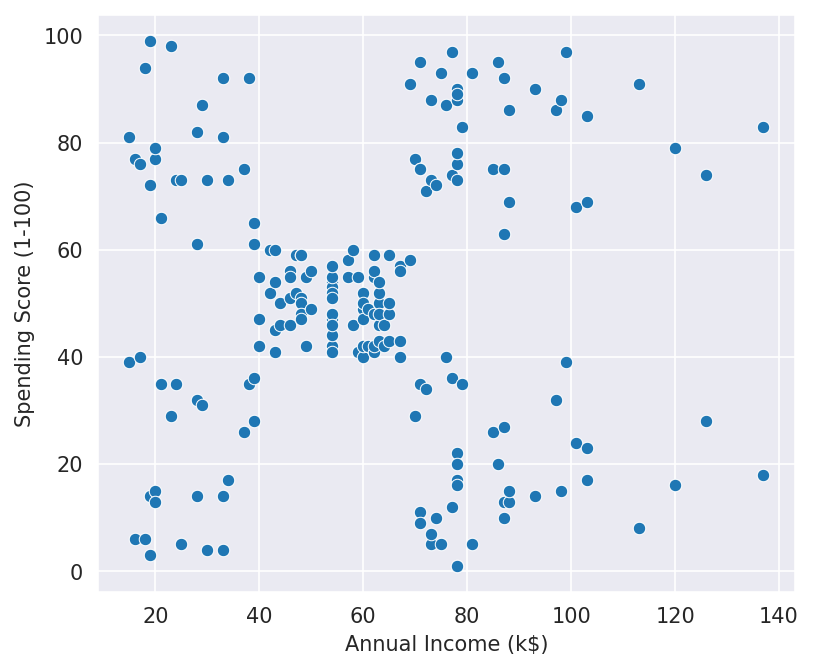

In [24]:
#Data visualization
sns.scatterplot(x= df['Annual Income (k$)'], y = df['Spending Score (1-100)'])
plt.show()


3. Data Preprocessing

In [25]:
#Standardization
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x = sc.fit_transform(df)
x[:10]


array([[-1.73899919, -0.43480148],
       [-1.73899919,  1.19570407],
       [-1.70082976, -1.71591298],
       [-1.70082976,  1.04041783],
       [-1.66266033, -0.39597992],
       [-1.66266033,  1.00159627],
       [-1.62449091, -1.71591298],
       [-1.62449091,  1.70038436],
       [-1.58632148, -1.83237767],
       [-1.58632148,  0.84631002]])

4. Model Devlopment (K-Means clustering )

In [26]:
from sklearn.cluster import KMeans
km = KMeans()# default 8 Cluster
yp = km.fit_predict(x)
yp


array([5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2,
       5, 2, 5, 2, 5, 7, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 5, 2, 7, 2, 7, 7,
       5, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
       7, 7, 7, 7, 7, 7, 7, 7, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 1,
       1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 6, 0, 6, 0, 6, 4, 6, 4, 6,
       0, 6, 4, 6, 4, 6, 4, 6, 4, 6, 0, 6, 4, 6, 0, 6, 4, 6, 4, 6, 4, 6,
       4, 6, 4, 6, 4, 6, 0, 6, 4, 6, 4, 6, 4, 6, 4, 6, 4, 6, 4, 6, 4, 6,
       4, 6, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3,
       4, 3], dtype=int32)

In [27]:
len(yp)


200

In [28]:
#cluster centre
km.cluster_centers_


array([[ 0.17856022, -0.39043398],
       [-0.03484644,  0.08129692],
       [-1.35921337,  1.19570407],
       [ 1.81769762,  1.26275949],
       [ 1.1010449 , -1.34346864],
       [-1.35185213, -1.19089759],
       [ 0.66703804,  1.23036618],
       [-0.6332424 ,  0.03576289]])

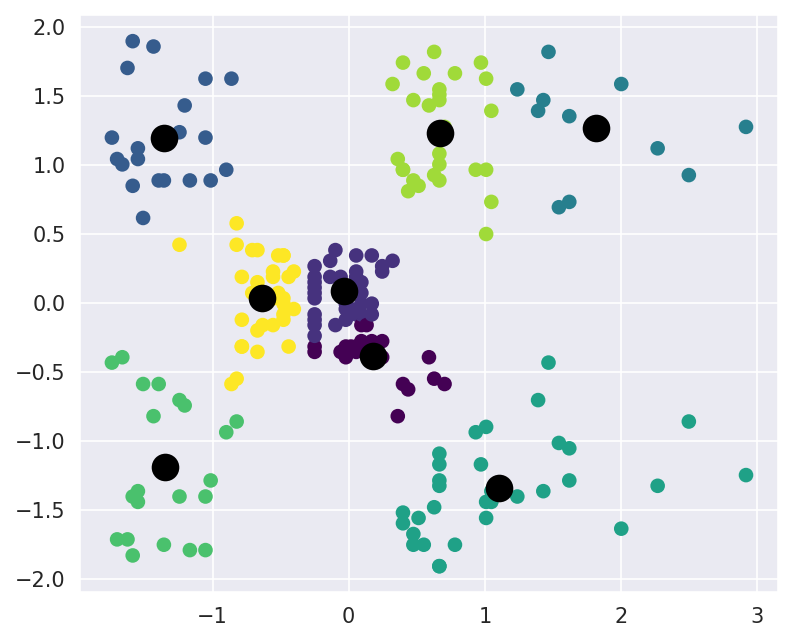

In [29]:
#Visualize the clusters- Scatter plot With Centroid of Each Cluster
plt.scatter(x[:, 0], x[:,1], c=yp, cmap='viridis')
plt.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1], c = 'black', s=150) #C - Centroid Colour S-Size of Centroid 100 to 200 range
plt.show()


In [30]:
km.inertia_ #- sum of squared distances of each sample to its nearest


43.60437067014667

Elbow graph /Elbow Curve

In [31]:
#WCSS (Within-Cluster Sum of Squares)
wcss = []
for i in range(1,20):
    km = KMeans (n_clusters=i)
    km.fit_predict(x)
    wcss.append(km.inertia_)


In [32]:
wcss



[399.99999999999994,
 276.44878073832723,
 195.50501014302682,
 109.22822707921345,
 65.57885579985046,
 55.52514743187719,
 44.91271612308711,
 43.186071450603926,
 32.406659676456606,
 32.73672249047857,
 26.69513669273,
 25.175352921991227,
 23.236752234077926,
 20.24488632767577,
 18.2762159496842,
 16.207817328633766,
 15.543928212350892,
 15.212353114193702,
 14.53569700720472]

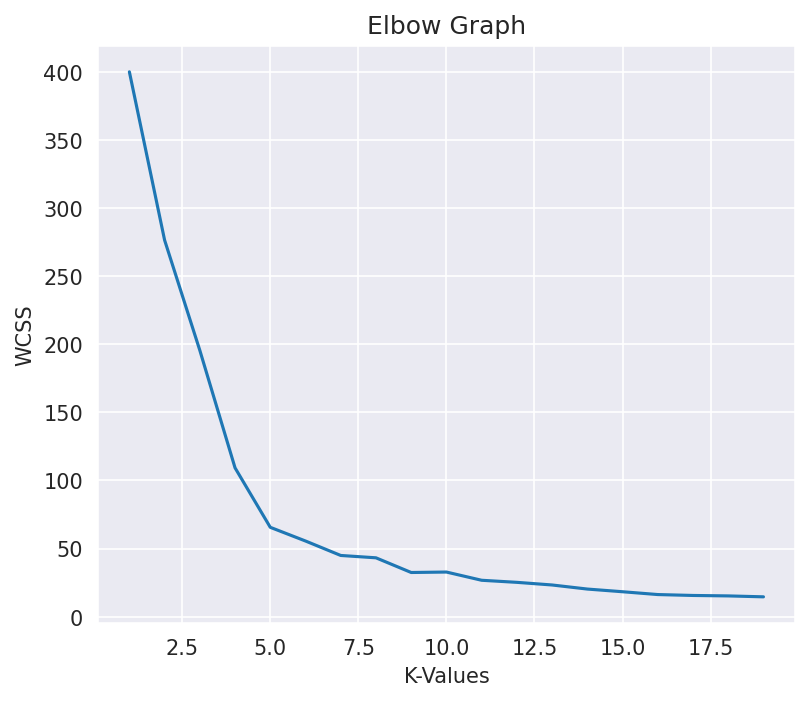

In [33]:
plt.plot(range (1,20), wcss)
plt.xlabel('K-Values')
plt.ylabel('WCSS')
plt.title('Elbow Graph')
plt.show()


5. Model Evaluation & Optimal K selection

K = 2, Silhouette Score = 0.321
K = 3, Silhouette Score = 0.467
K = 4, Silhouette Score = 0.494
K = 5, Silhouette Score = 0.555
K = 6, Silhouette Score = 0.540
K = 7, Silhouette Score = 0.528
K = 8, Silhouette Score = 0.455
K = 9, Silhouette Score = 0.457
K = 10, Silhouette Score = 0.443


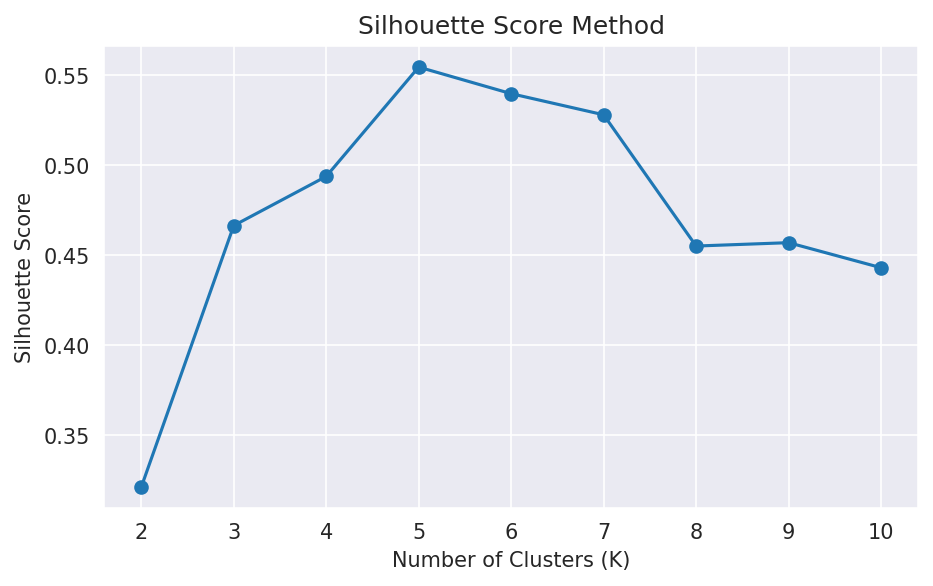

In [34]:
# Step 5: Silhouette Score Analysis
silhouette_scores = []
for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(x)
    score = silhouette_score (x, labels)
    silhouette_scores.append(score)
    print(f"K = {k}, Silhouette Score = {score:.3f}")

# Visualize Silhouette Scores
plt.figure(figsize=(7, 4))
plt.plot(range(2, 11), silhouette_scores, marker='o')
plt.title('Silhouette Score Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.xticks (range (2, 11))
plt.grid(True)
plt.show()
